# Лабораторная 2: графики

Читает `results/*.csv` (их пишет `scripts/bench.sh`) и строит время, ускорение
и эффективность в зависимости от числа исполнителей p (потоки OpenMP или
процессы MPI). Картинки сохраняются в `results/` для `README.md`.

- Точка - минимальное время по повторам, планка погрешности - до среднего.
- Кривая - сглаживающий кубический сплайн времени в координатах
  (log p, log T); кривые S и E получены из него же.
- S = T_посл / T_p, где T_посл - последовательная программа того же размера;
  E = S / p. Для MPI "всего" включает сбор результата на ранге 0, "счёт" -
  только цикл (для него среднее не замерялось).

Перезапуск из корня репозитория:
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace lab_2/plots.ipynb`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import make_smoothing_spline

RESULTS = Path("results")
df = pd.concat(pd.read_csv(f) for f in sorted(RESULTS.glob("*.csv")))
seq = df[df.impl == "seq"].set_index(["variant", "isize"])["min_s"]
df["t_seq"] = [seq[(v.split("-")[0], n)] for v, n in zip(df.variant, df.isize)]
df["speedup"] = df.t_seq / df.min_s
df["speedup_lo"] = df.t_seq / df.mean_s
df["efficiency"] = df.speedup / df.workers
df["efficiency_lo"] = df.speedup_lo / df.workers
df["speedup_comp"] = df.t_seq / df.comp_s
df["efficiency_comp"] = df.speedup_comp / df.workers
par = df[df.impl != "seq"]

In [2]:
LABELS = {"ref": "эталонный цикл", "1b": "вариант 1б", "2b": "вариант 2б",
          "3b": "вариант 3б"}
COLORS = {"OpenMP": "#2a78d6", "MPI, всего": "#eb6834",
          "MPI, счёт": "#1baf7a", "OpenMP, 2b-cols": "#eda100"}
LINES = {5000: "-", 1000: "--"}
MARKERS = {5000: "o", 1000: "s"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})


def fit_time(p, t):
    """Сглаживающий сплайн времени в координатах (log p, log T)."""
    spline = make_smoothing_spline(np.log(p), np.log(t), lam=0.01)
    ps = np.linspace(p.min(), p.max(), 200)
    return ps, np.exp(spline(np.log(ps)))


def series(variant):
    out = []
    sub = par[par.variant.str.startswith(variant)]
    for (name, impl), g in sub.groupby(["variant", "impl"]):
        tech = "OpenMP" if impl == "omp" else "MPI, всего"
        key = tech if name == variant else f"{tech}, {name}"
        out.append((key, g, "min_s", "mean_s"))
        if impl == "mpi":
            out.append(("MPI, счёт", g, "comp_s", None))
    return out


def errorbars(axes, x, values, others, color, marker, label):
    for ax, y, other in zip(axes, values, others):
        yerr = None
        if other is not None:
            yerr = [np.clip(y - other, 0, None), np.clip(other - y, 0, None)]
        ax.errorbar(x, y, yerr=yerr, fmt=marker, color=color, ms=5,
                    capsize=3, elinewidth=1, label=label)


def plot_variant(variant):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    for key, g, t_col, mean_col in series(variant):
        for n, gn in g.groupby("isize"):
            gn = gn.sort_values("workers")
            p = gn.workers.to_numpy(float)
            t = gn[t_col].to_numpy()
            t_seq = gn.t_seq.iloc[0]
            mean = None if mean_col is None else gn[mean_col].to_numpy()
            values = [t * 1e3, t_seq / t, t_seq / t / p]
            others = [None, None, None] if mean is None else [
                mean * 1e3, t_seq / mean, t_seq / mean / p]
            color = COLORS[key]
            errorbars(axes, p, values, others, color, MARKERS[n],
                      f"{key}, {n}x{n}")
            ps, tf = fit_time(p, t)
            for ax, y in zip(axes, [tf * 1e3, t_seq / tf, t_seq / tf / ps]):
                ax.plot(ps, y, color=color, ls=LINES[n], lw=1.8)
    p = sorted(par.workers.unique())
    axes[1].plot(p, p, color="#8a8984", ls=":", lw=1.5, label="идеал")
    axes[2].axhline(1, color="#8a8984", ls=":", lw=1.5)
    axes[0].set_yscale("log")
    titles = ["время, мс (лог. шкала)", "ускорение S", "эффективность E"]
    for ax, title in zip(axes, titles):
        ax.set_title(f"{LABELS[variant]}: {title}")
        ax.set_xlabel("исполнители p")
        ax.set_xticks(p)
    axes[2].set_ylim(0, 1.15)
    axes[1].legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    fig.savefig(RESULTS / f"{variant}.png")
    plt.show()

## Эталонный цикл (OpenMP и MPI)

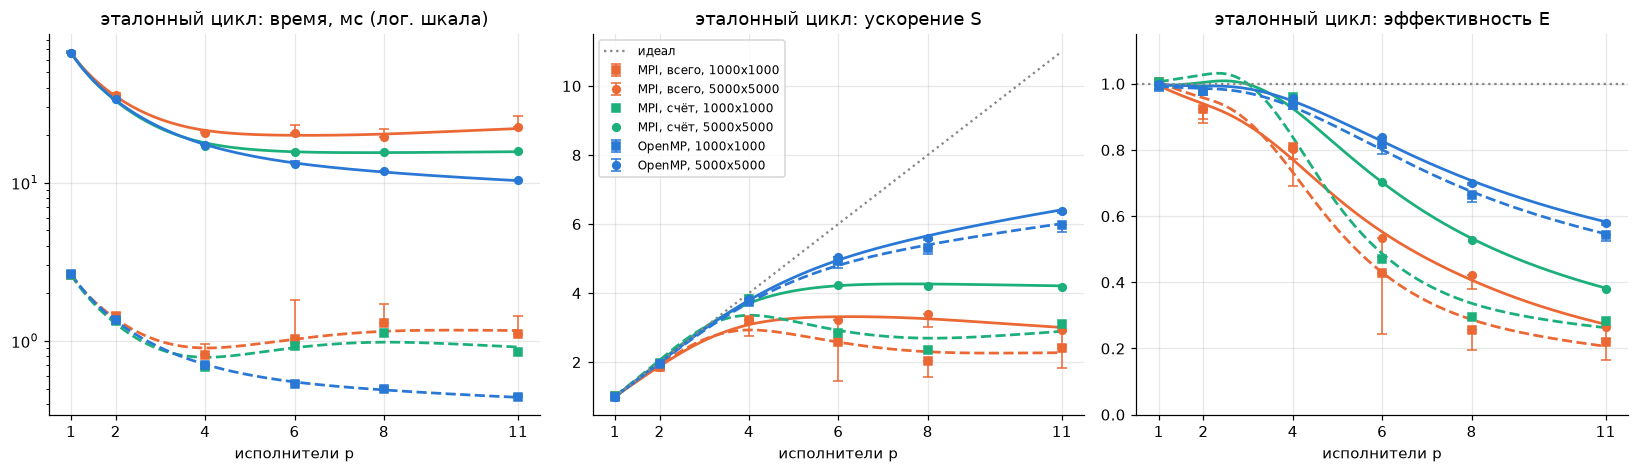

In [3]:
plot_variant("ref")

## Вариант 1б (MPI)

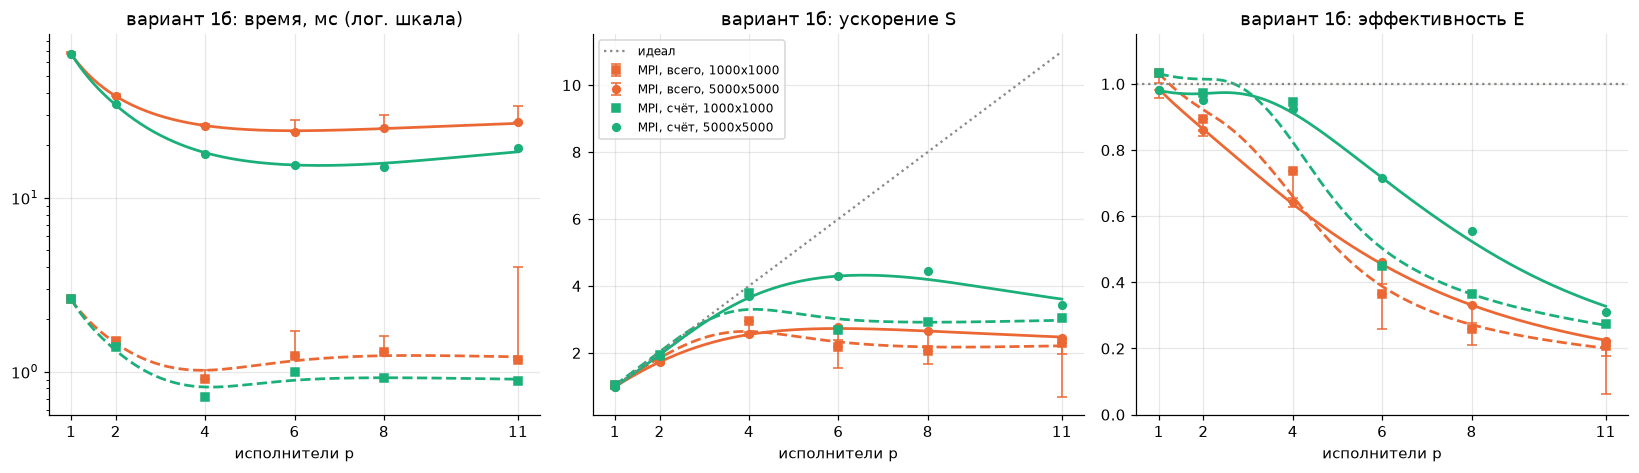

In [4]:
plot_variant("1b")

## Вариант 2б (OpenMP): блоки строк (`2b`) и деление по столбцам (`2b-cols`)

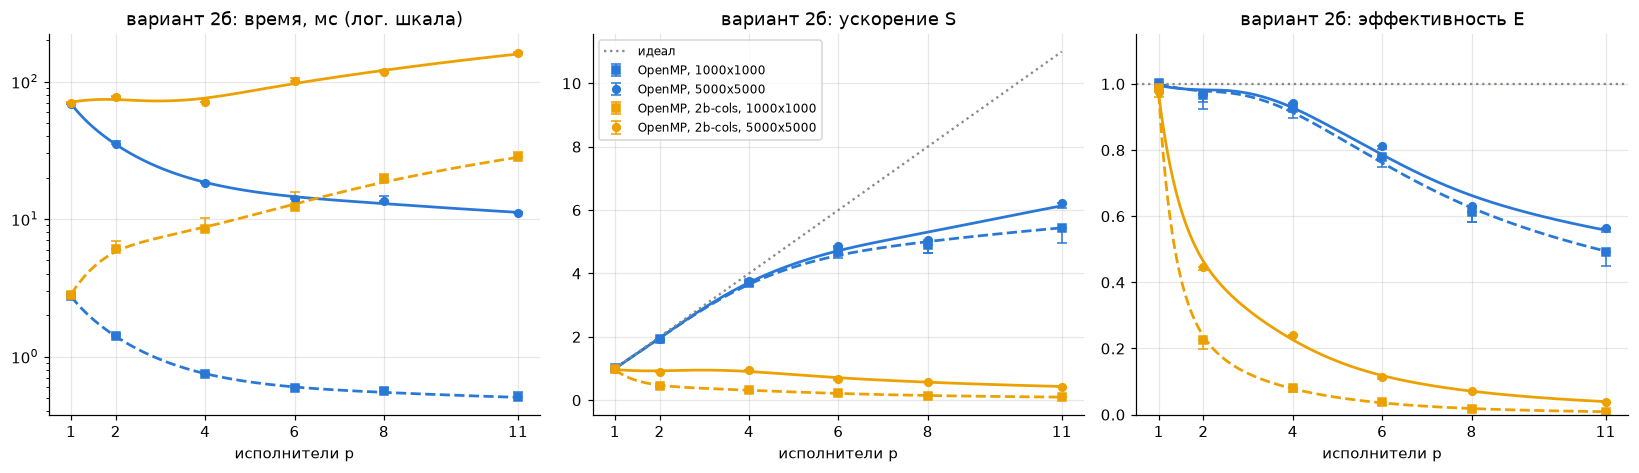

In [5]:
plot_variant("2b")

## Вариант 3б (OpenMP)

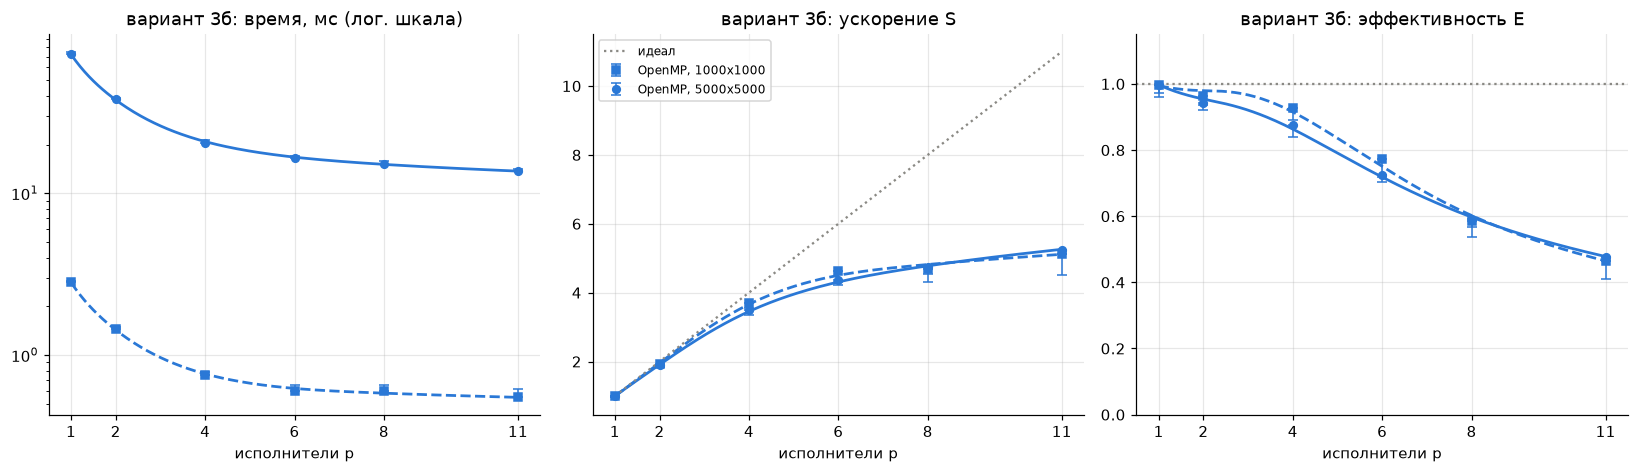

In [6]:
plot_variant("3b")

## Сводка при 5000 x 5000: ускорение и эффективность

In [7]:
big = par[par.isize == 5000].copy()
big["версия"] = big.variant + " " + big.impl
big.pivot_table(index="workers", columns="версия", values="speedup").round(2)

версия,1b mpi,2b omp,2b-cols omp,3b omp,ref mpi,ref omp
workers,,,,,,
1,0.98,1.00,0.98,1.00,0.99,1.00
2,1.72,1.94,0.89,1.89,1.85,1.97
4,2.57,3.77,0.97,3.51,3.21,3.83
6,2.77,4.88,0.68,4.35,3.20,5.03
8,2.65,5.04,0.58,4.73,3.38,5.61
11,2.44,6.21,0.43,5.23,2.93,6.37


In [8]:
big.pivot_table(index="workers", columns="версия", values="efficiency").round(2)

версия,1b mpi,2b omp,2b-cols omp,3b omp,ref mpi,ref omp
workers,,,,,,
1,0.98,1.00,0.98,1.00,0.99,1.00
2,0.86,0.97,0.45,0.94,0.92,0.98
4,0.64,0.94,0.24,0.88,0.80,0.96
6,0.46,0.81,0.11,0.73,0.53,0.84
8,0.33,0.63,0.07,0.59,0.42,0.70
11,0.22,0.56,0.04,0.48,0.27,0.58
